Page numbers are the printed pages of University Physics Vol. 1 and Vol. 2 in 00_books. In the PDF, add 12 (p. 288 is PDF page 300).

## Exercise 1: Potentials around a square

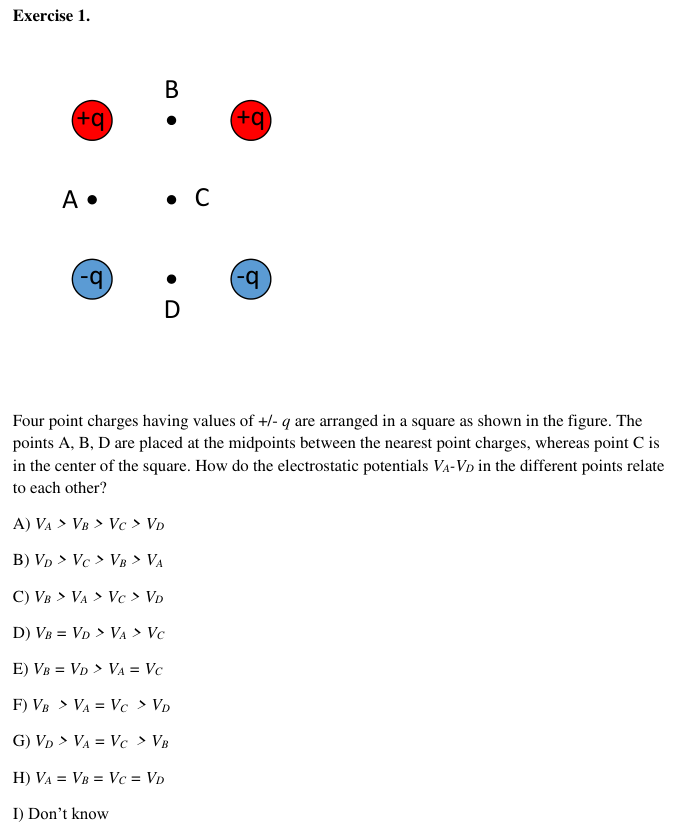

Book: University Physics Vol. 2, Section 7.3 Calculations of Electric Potential.

Potential of several point charges, Eq. 7.9 (p. 288):

$$V_P = k\sum_{i=1}^{N}\frac{q_i}{r_i}$$

Potential is a scalar, so only the signs of the charges matter, not directions.

Square with side $s$, bottom left corner at the origin. Only the order is asked, so $k = q = s = 1$.

In [1]:
k, q, s = 1, 1, 1

charges = [(+q, 0, s),   # top left
           (-q, 0, 0),   # bottom left
           (+q, s, s),   # top right
           (-q, s, 0)]   # bottom right

points = {"A": (0, s / 2), "B": (s / 2, s), "C": (s / 2, s / 2), "D": (s / 2, 0)}

for name, (Px, Py) in points.items():
    V = 0
    for qi, x, y in charges:
        r = ((Px - x)**2 + (Py - y)**2) ** 0.5
        V += k * qi / r
    print(f"V{name} = {V:.3f}")

VA = 0.000
VB = 2.211
VC = 0.000
VD = -2.211


Answer: F) $V_B > V_A = V_C > V_D$

A and C are each equally far from a $+q$ and a $-q$ of every pair, so everything cancels: $V_A = V_C = 0$. B sits closest to the two $+q$ charges, D closest to the two $-q$ charges.

## Exercise 2: Three charges on a line

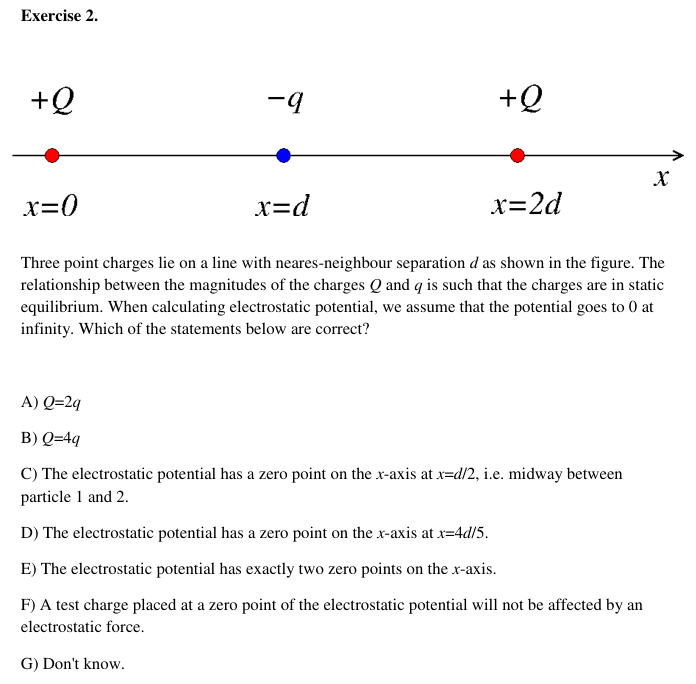

Book: University Physics Vol. 2.

1. Equilibrium: Coulomb's law, Eq. 5.1 (p. 179), summed as in Eq. 5.2 (p. 181). The middle charge is balanced by symmetry. The left $+Q$ is pulled right by $-q$ at distance $d$ and pushed left by $+Q$ at $2d$: $kQq/d^2 = kQ^2/(2d)^2$, so $Q = 4q$.
2. Potential, Eq. 7.9 (p. 288): $V(x) = kq\,[\,4/|x| - 1/|x-d| + 4/|x-2d|\,]$. Look for sign changes along the whole $x$-axis.
3. Field from potential, Eq. 7.13 (p. 296): $E_x = -\partial V/\partial x$. $V = 0$ at a point does not make the slope zero.

$k = q = d = 1$, so $V$ is in units of $kq/d$ and $E$ in units of $kq/d^2$.

In [2]:
import numpy as np

k, q, d = 1, 1, 1
Q = 4 * q                                  # from kQq/d^2 = kQ^2/(2d)^2

charges = [(Q, 0), (-q, d), (Q, 2 * d)]    # (charge, x position)

def V(x):
    return sum(k * qi / abs(x - xi) for qi, xi in charges)

def E(x):
    return sum(k * qi * (x - xi) / abs(x - xi)**3 for qi, xi in charges)

x = np.linspace(-20, 22, 4_200_001) + 1e-7  # never lands exactly on a charge
v = V(x)
zeros = x[:-1][np.sign(v[:-1]) != np.sign(v[1:])]

print("Q/q =", Q / q)
print(f"C) V(d/2)  = {V(0.5 * d):.3g}")
print(f"D) V(4d/5) = {V(0.8 * d):.3g}")
for z in zeros:
    print(f"E) V = 0 at x = {z:.3f} d,   F) field there: E = {E(z):.3g}")
print(f"   exact: (5 - sqrt 17) d = {5 - 17**0.5:.3f} d,  (sqrt 17 - 3) d = {17**0.5 - 3:.3f} d")

Q/q = 4.0
C) V(d/2)  = 8.67
D) V(4d/5) = 3.33
E) V = 0 at x = 0.877 d,   F) field there: E = 68
E) V = 0 at x = 1.123 d,   F) field there: E = -68
   exact: (5 - sqrt 17) d = 0.877 d,  (sqrt 17 - 3) d = 1.123 d


Correct: B and E.

- A) False: equilibrium gives $Q = 4q$.
- B) True.
- C) False: $V(d/2) = 8.67\,kq/d > 0$.
- D) False: $V(4d/5) = 3.33\,kq/d$. $x = 4d/5$ is where the first two charges cancel; it forgets the $+Q$ at $2d$.
- E) True: exactly two zeros, $x = (5-\sqrt{17})\,d \approx 0.877\,d$ and $x = (\sqrt{17}-3)\,d \approx 1.123\,d$, one on each side of $-q$. Outside the charges the nearest $+Q$ always wins, so $V > 0$ there.
- F) False: the field is not zero there ($|E| \approx 68\,kq/d^2$), so a test charge feels a force.

## Exercise 3: Drift velocity, resistance and mass of a cable

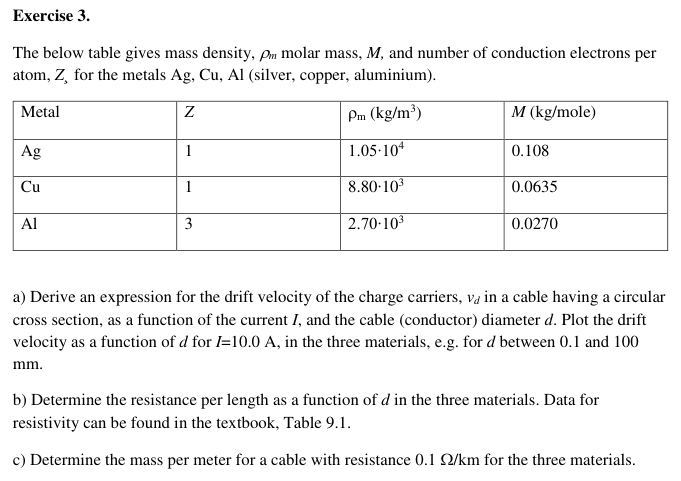

Book: University Physics Vol. 2, Chapter 9.

1. Drift velocity, Eq. 9.4 (p. 368): $v_d = I/(nqA)$ with $A = \pi d^2/4$. The free electron density is found as in Example 9.3 (p. 369): $n = Z\rho_m N_A/M$.
2. Resistance, Eq. 9.9 (p. 376): $R = \rho L/A$, so $R/L = 4\rho/(\pi d^2)$. Resistivities from Table 9.1 (p. 373): Ag $1.59$, Cu $1.68$, Al $2.65$, all $\times10^{-8}\ \Omega$ m.
3. $R/L = 0.1\ \Omega/\text{km} = 10^{-4}\ \Omega/\text{m}$ fixes $A = \rho/(R/L)$. The mass per metre is $\rho_m A$.

Ag: n = 5.85e+28 m^-3,  at d = 1 mm: v_d = 1.36 mm/s,  R/L = 0.0202 ohm/m
    c) d = 14.2 mm,  mass = 1.67 kg/m
Cu: n = 8.35e+28 m^-3,  at d = 1 mm: v_d = 0.952 mm/s,  R/L = 0.0214 ohm/m
    c) d = 14.6 mm,  mass = 1.48 kg/m
Al: n = 1.81e+29 m^-3,  at d = 1 mm: v_d = 0.44 mm/s,  R/L = 0.0337 ohm/m
    c) d = 18.4 mm,  mass = 0.716 kg/m


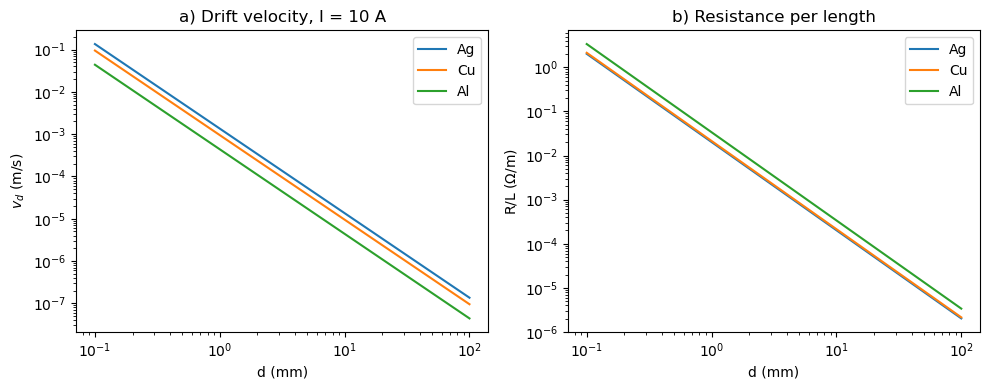

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

e = 1.602e-19        # C
NA = 6.022e23        # 1/mol
I = 10.0             # A
RL = 0.1e-3          # ohm/m, i.e. 0.1 ohm/km
d1 = 1e-3            # m, example diameter for the printed values

# name: (Z, density kg/m^3, M kg/mol, resistivity ohm m from Table 9.1)
metals = {"Ag": (1, 1.05e4, 0.108, 1.59e-8),
          "Cu": (1, 8.80e3, 0.0635, 1.68e-8),
          "Al": (3, 2.70e3, 0.0270, 2.65e-8)}

d = np.logspace(-4, -1, 200)     # m, 0.1 mm to 100 mm
A = math.pi * d**2 / 4
A1 = math.pi * d1**2 / 4

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, (Z, rho_m, M, rho) in metals.items():
    n = Z * rho_m * NA / M
    ax1.loglog(d * 1e3, I / (n * e * A), label=name)
    ax2.loglog(d * 1e3, rho / A, label=name)

    Ac = rho / RL
    print(f"{name}: n = {n:.3g} m^-3,  at d = 1 mm: v_d = {I / (n * e * A1) * 1e3:.3g} mm/s,  R/L = {rho / A1:.3g} ohm/m")
    print(f"    c) d = {math.sqrt(4 * Ac / math.pi) * 1e3:.3g} mm,  mass = {rho_m * Ac:.3g} kg/m")

ax1.set_xlabel("d (mm)")
ax1.set_ylabel("$v_d$ (m/s)")
ax1.set_title("a) Drift velocity, I = 10 A")
ax2.set_xlabel("d (mm)")
ax2.set_ylabel(r"R/L ($\Omega$/m)")
ax2.set_title("b) Resistance per length")
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

a) $$v_d = \frac{I}{neA} = \frac{4IM}{\pi Z\rho_m N_A e\,d^2}$$
A straight line with slope $-2$ on the log-log plot. At $d = 1$ mm: Ag 1.36 mm/s, Cu 0.952 mm/s, Al 0.44 mm/s.

b) $R/L = 4\rho/(\pi d^2)$. At $d = 1$ mm: Ag 0.0202, Cu 0.0214, Al 0.0337 $\Omega$/m.

c) Ag 1.67 kg/m ($d = 14.2$ mm), Cu 1.48 kg/m ($d = 14.6$ mm), Al 0.716 kg/m ($d = 18.4$ mm).

Mass per metre is $\rho_m\rho/(R/L)$, so density times resistivity decides. Al conducts worse but is so light that it needs half the mass of Cu.

## Exercise 4: HVDC power line

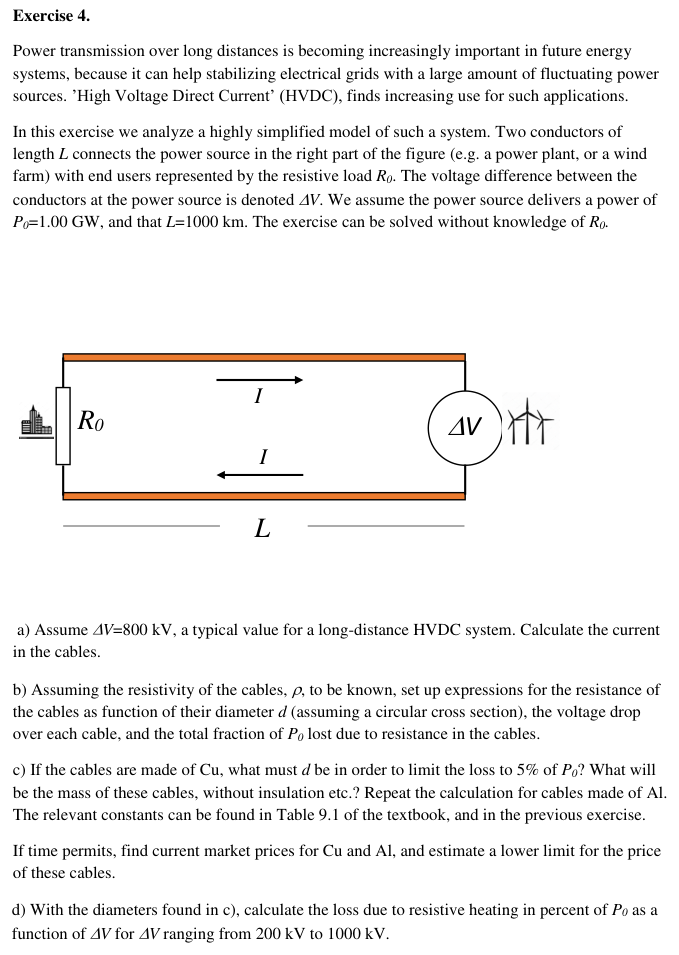

Book: University Physics Vol. 2, Chapter 9.

1. Power, Eq. 9.12 (p. 386): $P_0 = I\,\Delta V$, so $I = P_0/\Delta V$.
2. Each cable, Eq. 9.9 (p. 376): $R = \rho L/A = 4\rho L/(\pi d^2)$, and the voltage drop over it is $IR$. Heat in both cables, Eq. 9.13 (p. 386): $P_\text{loss} = 2I^2R$, so the lost fraction is $f = 2I^2R/P_0 = 2P_0R/\Delta V^2$.
3. $f = 5\,\%$ gives $R = fP_0/(2I^2)$. Then $A = \rho L/R$, $d = \sqrt{4A/\pi}$, and the mass of both cables is $2\rho_m A L$.

Resistivities from Table 9.1 (p. 373), densities from Exercise 3. Metal prices are not given: the code uses an assumed 10 USD/kg for Cu and 2.5 USD/kg for Al.

a) I = 1250 A
c) R per cable = 16 ohm,  voltage drop per cable = 20 kV
   Cu: d = 36.6 mm,  mass = 1.85e+04 t,  price > 185 million USD
   Al: d = 45.9 mm,  mass = 8.94e+03 t,  price > 22.4 million USD
d) loss at 200 kV = 80 %,  at 1000 kV = 3.2 %


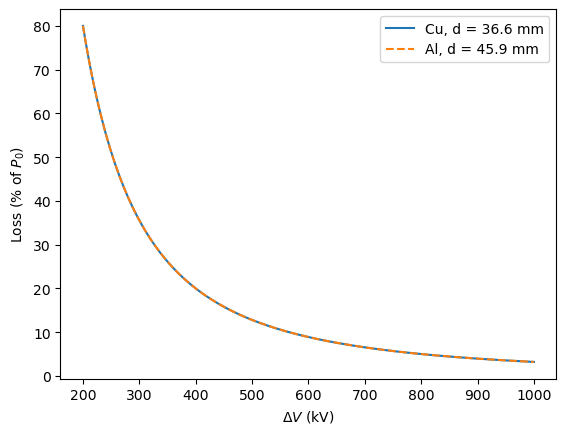

In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt

P0 = 1.00e9          # W
L = 1000e3           # m
dV = 800e3           # V
f = 0.05             # allowed loss fraction

# name: (resistivity ohm m, density kg/m^3, ASSUMED price USD/kg)
metals = {"Cu": (1.68e-8, 8.80e3, 10.0),
          "Al": (2.65e-8, 2.70e3, 2.5)}

I = P0 / dV
R = f * P0 / (2 * I**2)
print(f"a) I = {I:.4g} A")
print(f"c) R per cable = {R:.3g} ohm,  voltage drop per cable = {I * R / 1e3:.3g} kV")

V = np.linspace(200e3, 1000e3, 200)     # V
for (name, (rho, rho_m, price)), style in zip(metals.items(), ["-", "--"]):
    A = rho * L / R
    d = math.sqrt(4 * A / math.pi)
    mass = 2 * rho_m * A * L
    print(f"   {name}: d = {d * 1e3:.3g} mm,  mass = {mass / 1e3:.3g} t,  price > {mass * price / 1e6:.3g} million USD")

    loss = 2 * P0 * (rho * L / A) / V**2
    plt.plot(V / 1e3, loss * 100, style, label=f"{name}, d = {d * 1e3:.1f} mm")

print(f"d) loss at 200 kV = {2 * P0 * R / 200e3**2 * 100:.3g} %,  at 1000 kV = {2 * P0 * R / 1000e3**2 * 100:.3g} %")

plt.xlabel(r"$\Delta V$ (kV)")
plt.ylabel("Loss (% of $P_0$)")
plt.legend()
plt.show()

a) $I = 1250$ A

b) Per cable $R = \dfrac{4\rho L}{\pi d^2}$ and voltage drop $IR = \dfrac{4\rho L P_0}{\pi d^2\,\Delta V}$. Lost fraction:
$$\frac{P_\text{loss}}{P_0} = \frac{2I^2R}{P_0} = \frac{8\rho L P_0}{\pi d^2\,\Delta V^2}$$

c) 5 % loss needs $R = 16\ \Omega$ per cable (20 kV drop in each). Cu: $d \approx 36.6$ mm, mass $\approx 1.85\cdot10^4$ t. Al: $d \approx 45.9$ mm, mass $\approx 8.94\cdot10^3$ t.
With the assumed prices (10 USD/kg Cu, 2.5 USD/kg Al; check current market prices) the metal alone costs at least about 185 million USD for Cu and 22.4 million USD for Al.

d) Loss $= 5\,\% \cdot (800\text{ kV}/\Delta V)^2$: 80 % at 200 kV, 3.2 % at 1000 kV. The Cu and Al curves lie on top of each other because both cables were sized to the same $R = 16\ \Omega$.
The loss goes as $1/\Delta V^2$, which is why long lines use very high voltage.

## Exercise 5: Charges on a triangle

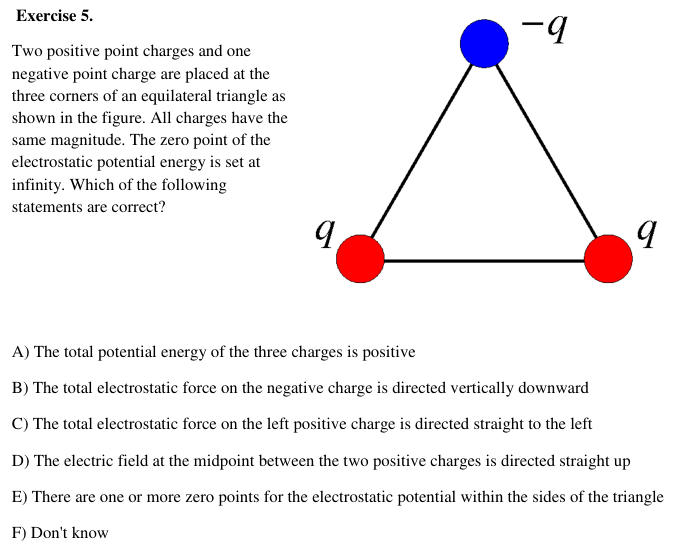

Book: University Physics Vol. 2.

1. Energy of the system, Eq. 7.3 (p. 274): sum of $kq_iq_j/r_{ij}$ over the three pairs.
2. Forces: Coulomb's law, Eq. 5.1 (p. 179), added as vectors, Eq. 5.2 (p. 181). Fields: Eq. 5.4 (p. 185), away from $+q$ and toward $-q$ (p. 186).
3. Potential: Eq. 7.9 (p. 288), checked along a side.

Left $+q$ at the origin, right $+q$ at $(a, 0)$, $-q$ at the top $(a/2,\ \sqrt3\,a/2)$. $k = q = a = 1$.

In [5]:
import math

k, q, a = 1, 1, 1
h = math.sqrt(3) / 2 * a

charges = [(+q, 0, 0),        # left
           (+q, a, 0),        # right
           (-q, a / 2, h)]    # top

def field(Px, Py, skip=None):
    Ex, Ey = 0, 0
    for i, (qi, x, y) in enumerate(charges):
        if i != skip:
            rx, ry = Px - x, Py - y
            r = math.hypot(rx, ry)
            Ex += k * qi * rx / r**3
            Ey += k * qi * ry / r**3
    return Ex, Ey

def show(label, Fx, Fy):
    angle = math.degrees(math.atan2(Fy, Fx))
    print(f"{label}: size {math.hypot(Fx, Fy):.3g}, direction {angle:.0f} deg from +x")

def potential(Px, Py):
    return sum(k * qi / math.hypot(Px - x, Py - y) for qi, x, y in charges)

U = sum(k * charges[i][0] * charges[j][0] / a for i, j in [(0, 1), (0, 2), (1, 2)])
print(f"A) U = {U:.3g}")

Ex, Ey = field(a / 2, h, skip=2)
show("B) F on -q", -q * Ex, -q * Ey)

Ex, Ey = field(0, 0, skip=0)
show("C) F on left +q", q * Ex, q * Ey)

show("D) E at midpoint", *field(a / 2, 0))

# walk along the left side from +q (t = 0) to -q (t = 1)
for t in [0.1, 0.5, 0.6, 0.7, 0.9]:
    print(f"E) t = {t}: V = {potential(t * a / 2, t * h):.3g}")

A) U = -1
B) F on -q: size 1.73, direction -90 deg from +x
C) F on left +q: size 1, direction 120 deg from +x
D) E at midpoint: size 1.33, direction 90 deg from +x
E) t = 0.1: V = 9.94
E) t = 0.5: V = 1.15
E) t = 0.6: V = 0.314
E) t = 0.7: V = -0.78
E) t = 0.9: V = -7.84


Correct: B, D and E.

- A) False: $U = k(q^2 - q^2 - q^2)/a = -kq^2/a < 0$.
- B) True: the pulls toward the two $+q$ charges are equal, so their sideways parts cancel and the net force is $1.73\,kq^2/a^2$ straight down ($-90°$).
- C) False: the push from the right $+q$ is to the left, but the pull toward $-q$ points up and to the right. The sum points up and to the left, at $120°$ from the $+x$ axis.
- D) True: the two $+q$ fields cancel at the midpoint, and the field of $-q$ points toward it, straight up ($90°$).
- E) True: along a side from $+q$ to $-q$, $V$ goes from $+\infty$ to $-\infty$, so it passes zero (here between $t = 0.6$ and $0.7$ of the way).

## Exercise 6: Potentials around a triangle of charges

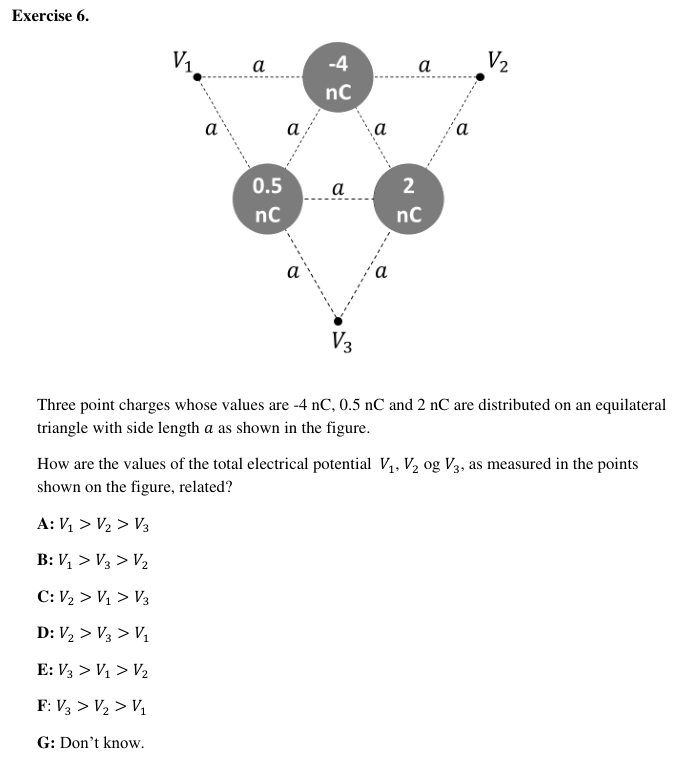

Book: University Physics Vol. 2, Eq. 7.9 (p. 288): $V = k\sum q_i/r_i$.

The three points and the three charges form a large triangle with side $2a$, with a charge in the middle of each side. Each point is $a$ from its two neighbouring charges and $\sqrt3\,a$ (the height of the large triangle) from the opposite one:

- $V_1$: neighbours $-4$ and $0.5$ nC, far charge $2$ nC.
- $V_2$: neighbours $-4$ and $2$ nC, far charge $0.5$ nC.
- $V_3$: neighbours $0.5$ and $2$ nC, far charge $-4$ nC.

$a$ is not given and only the order is asked, so $k = a = 1$ with charges in nC.

In [6]:
import math

k, a = 1, 1
far = math.sqrt(3) * a      # distance to the opposite charge

V1 = k * (-4 / a + 0.5 / a + 2 / far)
V2 = k * (-4 / a + 2 / a + 0.5 / far)
V3 = k * (0.5 / a + 2 / a - 4 / far)

print(f"V1 = {V1:.3g},  V2 = {V2:.3g},  V3 = {V3:.3g}")

V1 = -2.35,  V2 = -1.71,  V3 = 0.191


Answer: F) $V_3 > V_2 > V_1$

$V_3$ is the only point far from the $-4$ nC charge, so it is the highest. $V_1$ and $V_2$ both sit next to $-4$ nC, but $V_2$ has the 2 nC charge as its other neighbour instead of 0.5 nC.